# StrucIQ Beam Damage and Retrofit Dataset: quick start

This notebook loads the main tables of folder `06_design_space_population/tables` and reproduces four headline results:

1. how much of the static stiffness loss a vibration test registers, by damage stage;
2. the peak load of corroded beams relative to the same beams uncorroded;
3. the growth of deflection under sustained service load;
4. a simple baseline for benchmark task A1 (stiffness left from measurements).

Column definitions are in `06_design_space_population/data_dictionary.csv`. Requirements: Python 3 with `pandas`, `numpy`, `matplotlib` and `scikit-learn`.

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
T = '06_design_space_population/tables/'
beams = pd.read_csv(T + 'beams.csv')
stages = pd.read_csv(T + 'stages.csv')
print(len(beams), 'beams;', int(beams['run_ok'].sum()), 'completed at least three damage stages')
beams[['span_mm', 'b_mm', 'h_mm', 'pt_pct', 'grade_MPa', 'fy_nom_MPa', 'load', 'Py_hand_kN', 'Pmax_kN', 'f0_hz']].describe(include='all').round(2)

10000 beams; 9934 completed at least three damage stages


,span_mm,b_mm,h_mm,pt_pct,grade_MPa,fy_nom_MPa,load,Py_hand_kN,Pmax_kN,f0_hz
count,10000.00,10000.00,10000.00,10000.00,10000.00,10000.0,10000,10000.00,7865.00,9934.00
unique,NaN,NaN,NaN,NaN,NaN,NaN,2,NaN,NaN,NaN
top,NaN,NaN,NaN,NaN,NaN,NaN,four_point,NaN,NaN,NaN
freq,NaN,NaN,NaN,NaN,NaN,NaN,5000,NaN,NaN,NaN
mean,4000.00,250.00,377.51,0.93,30.00,457.5,NaN,179.50,189.31,42.63
std,1154.76,29.16,96.06,0.26,7.07,42.5,NaN,83.95,86.06,18.77
min,2000.40,200.00,250.00,0.41,20.00,415.0,NaN,37.18,41.63,14.20
25%,3000.20,227.50,300.00,0.73,25.00,415.0,NaN,118.15,125.56,28.41
50%,3999.85,250.00,375.00,0.90,30.00,457.5,NaN,162.90,172.18,37.10
75%,4999.92,272.50,450.00,1.11,35.00,500.0,NaN,220.69,233.43,52.12


## 1. Static and vibration stiffness by damage stage

`static_left` is the stiffness left from the diagnostic load cycle; `vib_left_breathing` is the stiffness a vibration test would register, from the breathing-crack frequency. Their ratio of losses, kappa, is the share of the static stiffness loss that vibration registers.

       damage_fraction  static_left  vib_left_breathing  kappa  \
stage                                                            
1                 0.43        0.834               0.928  0.480   
2                 0.62        0.576               0.777  0.543   
3                 0.80        0.432               0.674  0.577   
4                 0.89        0.388               0.636  0.595   
5                 1.00        0.363               0.604  0.620   

       service_crack_width_mm  
stage                          
1                       0.021  
2                       0.057  
3                       0.094  
4                       0.108  
5                       0.118  


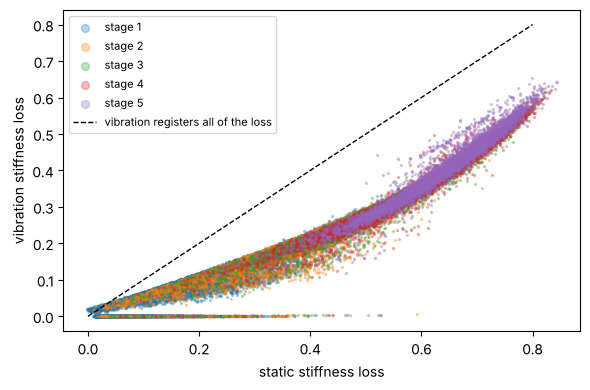

In [2]:
s = stages[stages['reached'] & (stages['stage'] > 0)].copy()
s['kappa'] = (1 - s['vib_left_breathing']) / (1 - s['static_left'])
summary = s.groupby('stage')[['damage_fraction', 'static_left', 'vib_left_breathing', 'kappa', 'service_crack_width_mm']].median().round(3)
print(summary)
fig, ax = plt.subplots(figsize=(6, 4))
for stg, g in s.groupby('stage'):
    ax.scatter(1 - g['static_left'], 1 - g['vib_left_breathing'], s=2, alpha=0.3, label='stage %d' % stg)
ax.plot([0, 0.8], [0, 0.8], 'k--', lw=1, label='vibration registers all of the loss')
ax.set_xlabel('static stiffness loss'); ax.set_ylabel('vibration stiffness loss'); ax.legend(markerscale=4, fontsize=8)
plt.tight_layout(); plt.show()

## 2. Corroded beams: peak load relative to the uncorroded beam

          count   mean    std    min     5%    50%    95%    max
psi_pct                                                         
5.0      1138.0  0.914  0.011  0.850  0.897  0.915  0.930  0.947
10.0     1136.0  0.842  0.019  0.591  0.815  0.842  0.870  0.917
15.0     1128.0  0.779  0.022  0.638  0.745  0.779  0.816  0.860


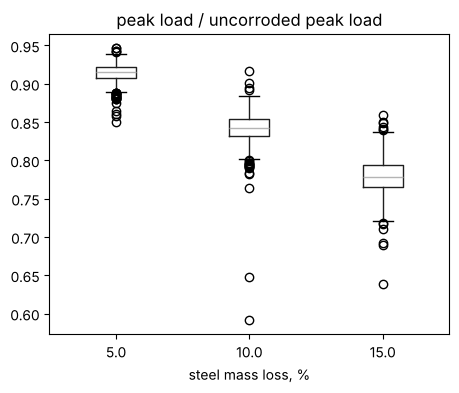

In [3]:
c = pd.read_csv(T + 'corrosion_runs.csv')
ok = c[c['run_ok'] & (c['push_complete'] == True)]
print(ok.groupby('psi_pct')['capacity_ratio'].describe(percentiles=[0.05, 0.5, 0.95]).round(3))
ok.boxplot(column='capacity_ratio', by='psi_pct', figsize=(5, 4), grid=False)
plt.suptitle(''); plt.title('peak load / uncorroded peak load'); plt.xlabel('steel mass loss, %'); plt.show()

## 3. Deflection under sustained service load

                relative_deflection  crack_width_mm  steel_stress_MPa
case     years                                                       
overload 0                    1.000           0.089           117.081
         1                    1.427           0.102           122.245
         10                   1.513           0.105           123.368
         50                   1.532           0.105           123.930
service  0                    1.000           0.017            32.111
         1                    2.325           0.073            89.825
         10                   2.624           0.083           100.161
         50                   2.691           0.085           102.090


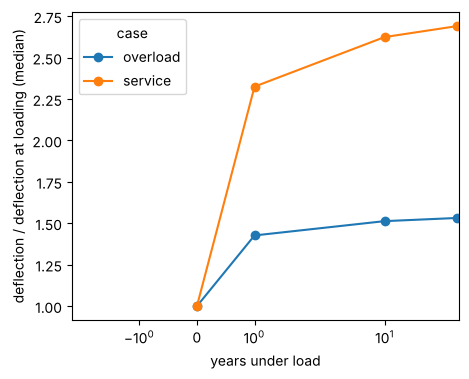

In [4]:
h = pd.read_csv(T + 'sustained_history.csv')
h0 = h[h['years'] == 0].set_index(['beam', 'case'])['deflection_mm']
h['relative_deflection'] = h['deflection_mm'] / h.set_index(['beam', 'case']).index.map(h0)
print(h.groupby(['case', 'years'])[['relative_deflection', 'crack_width_mm', 'steel_stress_MPa']].median().round(3))
h.groupby(['case', 'years'])['relative_deflection'].median().unstack(0).plot(marker='o', figsize=(5, 4))
plt.ylabel('deflection / deflection at loading (median)'); plt.xlabel('years under load'); plt.xscale('symlog'); plt.show()

## 4. Benchmark task A1: stiffness left from measurements (monitoring)

Inputs: beam design and one simulated instrument reading of frequency, service crack width, residual deflection and temperature, with the undamaged frequency of the same beam known. Target: `static_left`. The full benchmark, with both splits and task B, is `code/benchmarks.py`; this cell runs a short version on the random split.

In [5]:
from sklearn.ensemble import HistGradientBoostingRegressor
m = pd.read_csv(T + 'stages_measured.csv'); sp = pd.read_csv(T + 'splits.csv')
d = stages[stages['reached'] & (stages['stage'] > 0)].merge(m, on=['beam', 'stage', 'damage_kN', 'damage_fraction'])
f0 = m[m['stage'] == 0][['beam', 'f1_breathing_hz_measured']].rename(columns={'f1_breathing_hz_measured': 'f0_measured'})
d = d.merge(f0, on='beam').merge(beams, on='beam').merge(sp, on='beam')
d['ratio'] = (d['f1_breathing_hz_measured'] / d['f0_measured']) ** 2
X = d[['span_mm', 'b_mm', 'h_mm', 'cover_mm', 'd_bot_mm', 'pt_pct', 'span_over_d', 'grade_MPa', 'fy_nom_MPa',
       'f1_breathing_hz_measured', 'service_crack_width_mm_measured', 'residual_mm_measured', 'temperature_C', 'f0_measured', 'ratio']].copy()
X['four_point'] = (d['load'] == 'four_point').astype(int); y = d['static_left']
tr, te = d['split_random'] == 'train', d['split_random'] == 'test'
model = HistGradientBoostingRegressor(random_state=0).fit(X[tr], y[tr])
print('mean absolute error, percentage points of stiffness left:')
print('  frequency ratio read as stiffness left:', round(float((d.loc[te, 'ratio'].clip(0, 1.2) - y[te]).abs().mean() * 100), 2))
print('  gradient boosting on all inputs:      ', round(float((model.predict(X[te]) - y[te]).abs().mean() * 100), 2))

mean absolute error, percentage points of stiffness left:
  frequency ratio read as stiffness left: 19.89
  gradient boosting on all inputs:       2.92


## Where to go next

- `tables/retrofit.csv` and `retrofit_envelopes.csv`: response after laminate, plate and jacket strengthening (beams 0 to 999).
- `tables/corrosion_stages.csv`: staged-damage records of the corroded beams, for telling corrosion from overload damage.
- `tables/fatigue.csv`: Eurocode 2 fatigue life of the tension steel by stage.
- `tables/envelopes.csv`: 40-point load-deflection curves (use rows with `valid` true).
- Quality flags (`run_ok`, `reached`, `push_complete`, `push_diverged`, `frequency_rise`, `capacity_gain_valid`) are described in the README; filter on them before fitting models.